# Challenge 1 – Apartment Rental Price Prediction (CAI 4105, Team 11)
Goal: predict monthly `price` (regression, primary metric **RMSE**).
Workflow: load → EDA → hold out validation data → preprocessing pipeline → CV strategy → model comparison and Grid Search → final model validation → `predictions.csv`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import KFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error

SEED = 42
train = pd.read_csv("../data/challenge1_train.csv")
test  = pd.read_csv("../data/challenge1_test.csv")
print(train.shape, test.shape)
train.head()

(7398, 10) (2467, 9)


,ID,price,bathrooms,bedrooms,square_feet,latitude,longitude,category,has_photo,state
0,2,925,1.0,0,116,47.6160,-122.3275,housing/rent/apartment,Thumbnail,WA
1,3,2475,1.0,0,130,40.7629,-73.9885,housing/rent/apartment,Thumbnail,NY
2,5,1695,1.0,0,190,37.7599,-122.4379,housing/rent/apartment,Thumbnail,CA
3,6,1560,1.0,1,200,35.0847,-77.0609,housing/rent/apartment,Thumbnail,NC
4,7,1560,1.0,1,200,35.0960,-77.0272,housing/rent/apartment,Thumbnail,NC


## 1. Data exploration

In [2]:
print(train.isna().sum().sum(), "missing in train;", test.isna().sum().sum(), "in test")
print(train.drop(columns="ID").describe().T.round(2))
for c in ["category","has_photo"]: print(train[c].value_counts().to_dict())
print("states: train", train.state.nunique(), "| test-only states:", set(test.state)-set(train.state))

0 missing in train; 0 in test
              count     mean     std     min     25%      50%      75%  \
price        7398.0  1462.81  821.58  200.00  949.00  1273.50  1695.00   
bathrooms    7398.0     1.38    0.60    1.00    1.00     1.00     2.00   
bedrooms     7398.0     1.74    0.94    0.00    1.00     2.00     2.00   
square_feet  7398.0   940.94  502.25  116.00  650.00   807.50  1100.00   
latitude     7398.0    37.65    5.52   21.32   33.60    38.77    41.35   
longitude    7398.0   -94.41   15.72 -158.02  -98.53   -93.65   -81.64   

                 max  
price        8800.00  
bathrooms       7.00  
bedrooms        9.00  
square_feet  5921.00  
latitude       61.59  
longitude     -70.35  
{'housing/rent/apartment': 7395, 'housing/rent/home': 2, 'housing/rent/short_term': 1}
{'Thumbnail': 6566, 'Yes': 693, 'No': 139}
states: train 50 | test-only states: {'WY'}


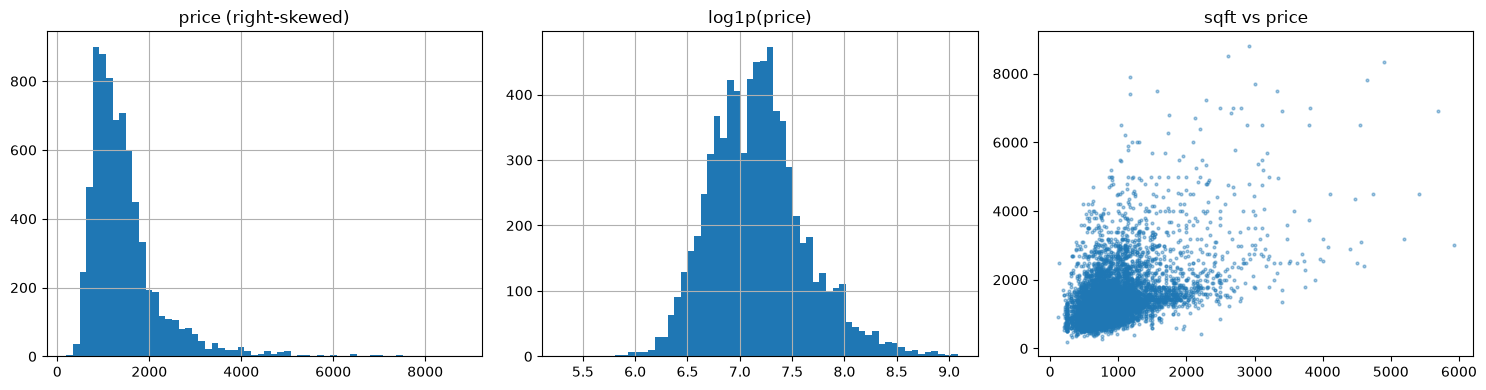

price          1.00
bathrooms      0.44
bedrooms       0.36
square_feet    0.48
latitude       0.04
longitude     -0.19
Name: price, dtype: float64
       count  median
state               
HI        10  2850.0
CA       688  2325.0
MA       119  2274.0
WV         1  2000.0
DC        62  1966.0
ME         2  1862.5
NJ       294  1811.0
WA       375  1675.0


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15,4))
train.price.hist(bins=60, ax=ax[0]); ax[0].set_title("price (right-skewed)")
np.log1p(train.price).hist(bins=60, ax=ax[1]); ax[1].set_title("log1p(price)")
ax[2].scatter(train.square_feet, train.price, s=4, alpha=.4); ax[2].set_title("sqft vs price")
plt.tight_layout(); plt.show()
print(train[["price","bathrooms","bedrooms","square_feet","latitude","longitude"]].corr()["price"].round(2))
print(train.groupby("state").price.agg(["count","median"]).sort_values("median",ascending=False).head(8))

**Findings.** No missing values (data already cleaned). Price is strongly right-skewed (log helps), and location (state / lat-lon) matters a lot.
`category` is ~constant (7395 of 7398 are `apartment`) so it carries no signal and is dropped. `ID` is dropped (not a predictor). `WY` appears only in test, so one-hot encoding uses `handle_unknown="ignore"`.

## 2. Preprocessing & validation strategy
* **Preprocessing lives inside sklearn Pipelines**, so scaling/encoding are fit only on the training folds (no leakage).
* Linear model: standardize numerics + one-hot categoricals. Tree models: no scaling needed.
* **Validation: 5-fold shuffled KFold (seed 42) on the training data only**, used for every model, every grid search and the final choice. Metric: RMSE on the original dollar scale. We report train RMSE vs CV RMSE to diagnose over/underfitting.
* Test set is never touched until the final prediction.

In [4]:
from sklearn.model_selection import train_test_split

X_all = train.drop(columns=["ID","price","category"]); y_all = train["price"]
X, X_valid, y, y_valid = train_test_split(X_all, y_all, test_size=0.2, random_state=SEED)
X_test = test.drop(columns=["ID","category"])
num = ["bathrooms","bedrooms","square_feet","latitude","longitude"]; cat = ["has_photo","state"]
cv = KFold(5, shuffle=True, random_state=SEED)

def prep(scale):
    return ColumnTransformer([("num", StandardScaler() if scale else "passthrough", num),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])

def evaluate(name, model, X=X):
    r = cross_validate(model, X, y, cv=cv, scoring="neg_root_mean_squared_error", return_train_score=True, n_jobs=-1)
    return dict(model=name, train_RMSE=-r["train_score"].mean(), cv_RMSE=-r["test_score"].mean(), cv_std=r["test_score"].std())

## 3. Baseline: the four required models (+ extras)

In [5]:
base = {
 "Mean baseline (dummy)": None,
 "Linear Regression": Pipeline([("p",prep(True)),("m",LinearRegression())]),
 "Decision Tree":      Pipeline([("p",prep(False)),("m",DecisionTreeRegressor(random_state=SEED))]),
 "Random Forest":      Pipeline([("p",prep(False)),("m",RandomForestRegressor(n_estimators=200,random_state=SEED,n_jobs=-1))]),
 "Gradient Boosting":  Pipeline([("p",prep(False)),("m",GradientBoostingRegressor(random_state=SEED))]),
 "Hist Gradient Boosting (extra)": Pipeline([("p",prep(False)),("m",HistGradientBoostingRegressor(random_state=SEED))]),
}
from sklearn.dummy import DummyRegressor
base["Mean baseline (dummy)"] = DummyRegressor()
res = pd.DataFrame([evaluate(k,v) for k,v in base.items()]).round(1)
res

,model,train_RMSE,cv_RMSE,cv_std
0,Mean baseline (dummy),814.0,813.3,36.5
1,Linear Regression,514.4,521.0,32.0
2,Decision Tree,35.8,557.9,11.7
3,Random Forest,159.3,423.3,19.9
4,Gradient Boosting,396.3,464.2,26.3
5,Hist Gradient Boosting (extra),311.6,409.9,15.8


Reading the table: the default Decision Tree has a tiny train RMSE vs a much larger CV RMSE → **overfits**. Linear Regression has similar train/CV error but a high level → **underfits** (price vs sqft/location is non-linear). Ensembles do best.

## 4. Improvement: feature engineering + log target + Grid Search
Feature engineering (all inside the pipeline, row-wise so no leakage): `log_sqft`, `sqft_per_bedroom`, `total_rooms`, `bath_per_bed`.
Target transform: train on `log1p(price)` and invert with `expm1` (`TransformedTargetRegressor`), RMSE still measured in dollars.

In [6]:
def add_feats(d):
    d = d.copy()
    d["log_sqft"] = np.log1p(d.square_feet)
    d["total_rooms"] = d.bedrooms + d.bathrooms
    d["sqft_per_bed"] = d.square_feet / (d.bedrooms + 1)
    d["bath_per_bed"] = d.bathrooms / (d.bedrooms + 1)
    return d
FE = FunctionTransformer(add_feats)
num2 = num + ["log_sqft","total_rooms","sqft_per_bed","bath_per_bed"]
def prep2(scale):
    return ColumnTransformer([("num", StandardScaler() if scale else "passthrough", num2),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
def pipe(model, scale=False, logy=True):
    p = Pipeline([("fe",FE),("p",prep2(scale)),("m",model)])
    return TransformedTargetRegressor(p, func=np.log1p, inverse_func=np.expm1) if logy else p

fe_check = pd.DataFrame([
  evaluate("RF raw target",      pipe(RandomForestRegressor(200,random_state=SEED,n_jobs=-1), logy=False)),
  evaluate("RF + FE + log y",    pipe(RandomForestRegressor(200,random_state=SEED,n_jobs=-1))),
  evaluate("GB raw target",      pipe(GradientBoostingRegressor(random_state=SEED), logy=False)),
  evaluate("GB + FE + log y",    pipe(GradientBoostingRegressor(random_state=SEED))),
  evaluate("LinReg + FE + log y",pipe(LinearRegression(), scale=True)),
]).round(1); fe_check

,model,train_RMSE,cv_RMSE,cv_std
0,RF raw target,161.8,424.6,20.7
1,RF + FE + log y,174.8,419.5,22.7
2,GB raw target,388.5,455.7,27.9
3,GB + FE + log y,421.5,463.2,29.1
4,LinReg + FE + log y,500.9,506.2,26.9


In [7]:
grids = {
 "Ridge": (pipe(Ridge(), scale=True), {"regressor__m__alpha":[0.1,1,10,100]}),
 "Decision Tree": (pipe(DecisionTreeRegressor(random_state=SEED)),
     {"regressor__m__max_depth":[4,6,8,10,14],"regressor__m__min_samples_leaf":[1,5,10,20]}),
 "Random Forest": (pipe(RandomForestRegressor(n_estimators=200,random_state=SEED,n_jobs=-1)),
     {"regressor__m__max_depth":[None,20],"regressor__m__min_samples_leaf":[1,3],"regressor__m__max_features":[0.5,1.0]}),
 "Gradient Boosting": (pipe(GradientBoostingRegressor(random_state=SEED)),
     {"regressor__m__n_estimators":[300,600],"regressor__m__learning_rate":[0.03,0.08],"regressor__m__max_depth":[3,5],"regressor__m__subsample":[0.8]}),
 "Hist Gradient Boosting": (pipe(HistGradientBoostingRegressor(random_state=SEED)),
     {"regressor__m__learning_rate":[0.03,0.06,0.1],"regressor__m__max_iter":[300,600],"regressor__m__max_leaf_nodes":[15,31,63],"regressor__m__l2_regularization":[0,1]}),
}
best, rows = {}, []
for name,(est,g) in grids.items():
    gs = GridSearchCV(est, g, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1, return_train_score=True).fit(X,y)
    best[name]=gs.best_estimator_; i=gs.best_index_
    rows.append(dict(model=name, train_RMSE=-gs.cv_results_["mean_train_score"][i], cv_RMSE=-gs.best_score_, cv_std=gs.cv_results_["std_test_score"][i], best_params={k.split("__")[-1]:v for k,v in gs.best_params_.items()}))
tuned = pd.DataFrame(rows).sort_values("cv_RMSE"); tuned.round(1)

,model,train_RMSE,cv_RMSE,cv_std,best_params
3,Gradient Boosting,173.1,389.9,18.7,"{'learning_rate': 0.08, 'max_depth': 5, 'n_est..."
4,Hist Gradient Boosting,249.9,390.3,13.0,"{'l2_regularization': 1, 'learning_rate': 0.1,..."
2,Random Forest,185.3,419.2,22.6,"{'max_depth': 20, 'max_features': 1.0, 'min_sa..."
1,Decision Tree,404.2,488.1,27.2,"{'max_depth': 14, 'min_samples_leaf': 10}"
0,Ridge,501.0,506.2,26.9,{'alpha': 0.1}


## 5. Final comparison & model selection

In [8]:
summary = pd.concat([res.assign(stage="baseline"), tuned.drop(columns="best_params").round(1).assign(stage="tuned (FE+log y+GridSearch)")]).sort_values("cv_RMSE")
summary[["stage","model","train_RMSE","cv_RMSE","cv_std"]].reset_index(drop=True)

,stage,model,train_RMSE,cv_RMSE,cv_std
0,tuned (FE+log y+GridSearch),Gradient Boosting,173.1,389.9,18.7
1,tuned (FE+log y+GridSearch),Hist Gradient Boosting,249.9,390.3,13.0
2,baseline,Hist Gradient Boosting (extra),311.6,409.9,15.8
3,tuned (FE+log y+GridSearch),Random Forest,185.3,419.2,22.6
4,baseline,Random Forest,159.3,423.3,19.9
5,baseline,Gradient Boosting,396.3,464.2,26.3
6,tuned (FE+log y+GridSearch),Decision Tree,404.2,488.1,27.2
7,tuned (FE+log y+GridSearch),Ridge,501.0,506.2,26.9
8,baseline,Linear Regression,514.4,521.0,32.0
9,baseline,Decision Tree,35.8,557.9,11.7


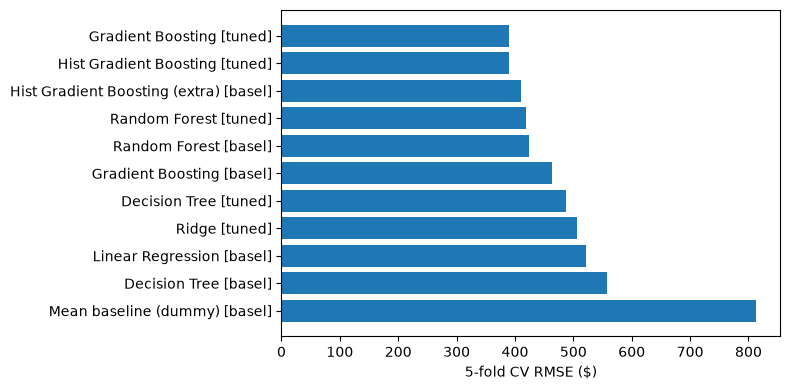

In [9]:
plt.figure(figsize=(8,4)); s=summary.sort_values("cv_RMSE",ascending=False)
plt.barh(s.model+" ["+s.stage.str[:5]+"]", s.cv_RMSE); plt.xlabel("5-fold CV RMSE ($)"); plt.tight_layout(); plt.show()

In [10]:
FINAL_NAME = tuned.iloc[0].model
final = best[FINAL_NAME]
print("Final model:", FINAL_NAME, "| CV RMSE =", round(tuned.iloc[0].cv_RMSE,1))
# Quick interpretability check: permutation importance on a held-out fold
from sklearn.inspection import permutation_importance
tr, va = next(iter(cv.split(X)))
m = __import__("sklearn").base.clone(final).fit(X.iloc[tr], y.iloc[tr])
pi = permutation_importance(m, X.iloc[va], y.iloc[va], scoring="neg_root_mean_squared_error", n_repeats=5, random_state=SEED)
pd.Series(pi.importances_mean, X.columns).sort_values(ascending=False).round(1)

Final model: Gradient Boosting | CV RMSE = 389.9


longitude      378.2
square_feet    229.7
latitude       182.1
state          168.8
bathrooms       60.4
bedrooms        46.4
has_photo        1.7
dtype: float64

## Held-out validation of the final model
The labeled training data was split once into a development set and an untouched 20% validation set before model comparison and tuning. The validation set is used only here, after choosing the final model. RMSE is the primary metric; MAE and R² provide additional context. The mean baseline helps show whether the model adds value. The competition test set has no labels, so its true performance cannot be measured in this notebook.

,RMSE,MAE,R2
model,,,
Gradient Boosting,420.08,237.14,0.76
Mean baseline,850.87,563.20,-0.00


Holdout RMSE improvement over the mean baseline: 50.6%


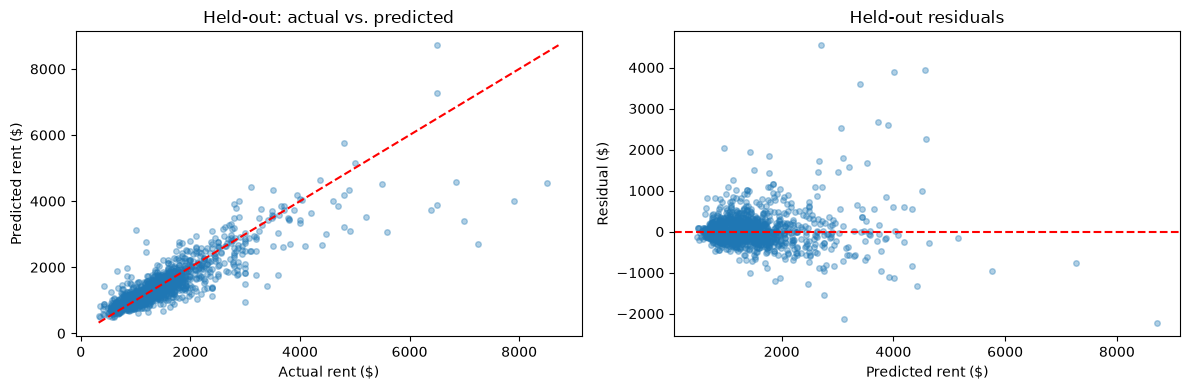

In [11]:
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

validation_model = clone(final).fit(X, y)
validation_pred = validation_model.predict(X_valid)
baseline = DummyRegressor(strategy="mean").fit(X, y)
baseline_pred = baseline.predict(X_valid)

validation_results = pd.DataFrame([
    {"model": FINAL_NAME,
     "RMSE": np.sqrt(mean_squared_error(y_valid, validation_pred)),
     "MAE": mean_absolute_error(y_valid, validation_pred),
     "R2": r2_score(y_valid, validation_pred)},
    {"model": "Mean baseline",
     "RMSE": np.sqrt(mean_squared_error(y_valid, baseline_pred)),
     "MAE": mean_absolute_error(y_valid, baseline_pred),
     "R2": r2_score(y_valid, baseline_pred)},
]).set_index("model").round(2)
display(validation_results)
rmse_gain = 1 - validation_results.loc[FINAL_NAME, "RMSE"] / validation_results.loc["Mean baseline", "RMSE"]
print(f"Holdout RMSE improvement over the mean baseline: {rmse_gain:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_valid, validation_pred, alpha=0.35, s=16)
bounds = [min(y_valid.min(), validation_pred.min()), max(y_valid.max(), validation_pred.max())]
axes[0].plot(bounds, bounds, "r--")
axes[0].set(xlabel="Actual rent ($)", ylabel="Predicted rent ($)", title="Held-out: actual vs. predicted")
axes[1].scatter(validation_pred, y_valid - validation_pred, alpha=0.35, s=16)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="Predicted rent ($)", ylabel="Residual ($)", title="Held-out residuals")
plt.tight_layout()
plt.show()

### Justification
* **Validation performance:** the final model's RMSE, MAE, and R² on an untouched validation set are compared with a mean-prediction baseline in the table below; CV RMSE is used for model selection.
* **Over/underfitting:** compare train and CV RMSE in the model tables; a large gap indicates overfitting, while high values on both suggest underfitting.
* **Complexity / compute / interpretability:** the selected ensemble is more complex and less interpretable than linear regression; the permutation importance above summarizes its drivers, and the held-out RMSE quantifies its benefit over the baseline.

## 6. Train on all training data & generate predictions

In [12]:
final.fit(X_all, y_all)
pred = final.predict(X_test)
out = pd.DataFrame({"ID": test.ID, "price": np.round(pred, 2)})
assert len(out)==len(test)==2467 and out.ID.is_unique and out.price.notna().all()
out.to_csv("predictions.csv", index=False)
print(out.price.describe().round(1)); out.head()

count    2467.0
mean     1445.6
std       759.8
min       435.1
25%       981.9
50%      1236.8
75%      1637.2
max      8454.6
Name: price, dtype: float64


,ID,price
0,1,1447.80
1,4,1661.81
2,9,919.69
3,11,850.56
4,13,637.70
